Phase 4: Train/Test Split
Since this is time series data, we never shuffle. We take the first 80% chronologically as train and the last 20% as test. To prevent target leakage (our target uses 5-day forward returns), we insert a 5-day gap between train and test.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (14, 5)

df = pd.read_csv('../data/processed/nsei_features.csv', parse_dates=['Date'], index_col='Date')
print(f"Loaded: {df.shape}")
print(f"Date range: {df.index.min().date()} → {df.index.max().date()}")

Loaded: (1612, 36)
Date range: 2020-03-13 → 2026-09-23


4.1 Define Features and Target
We exclude Target_Volatility (the target), Regime (categorical, derived from target-leaking rolling vol), and raw OHLCV columns that would leak future info if unshifted.

In [2]:
TARGET = 'Target_Volatility'

# Columns to exclude from features
# 'Regime' is derived from rolling vol, and OHLCV raw values are not stationary
EXCLUDE = [
    TARGET,
    'Regime',
    'Open', 'High', 'Low', 'Close', 'Volume',   # raw levels (non-stationary)
    'High_Low_Range', 'Volume_Change',
    'MA_5', 'MA_20', 'MA_50',                    # raw MA levels (non-stationary)
    'Volume_MA_5', 'Volume_MA_20',
    'MACD', 'MACD_signal',                       # MACD levels depend on price scale
]

FEATURES = [c for c in df.columns if c not in EXCLUDE]
print(f"Number of features: {len(FEATURES)}")
for f in FEATURES:
    print(f" - {f}")

Number of features: 20
 - Return
 - Return_lag1
 - Return_lag2
 - Return_lag3
 - Return_lag5
 - Return_lag10
 - AbsReturn_lag1
 - AbsReturn_lag2
 - AbsReturn_lag3
 - AbsReturn_lag5
 - Vol_rolling_5
 - Vol_rolling_10
 - Vol_rolling_20
 - AbsReturn_roll_5
 - Close_MA20_ratio
 - Close_MA50_ratio
 - RSI_14
 - MACD_hist
 - ATR_14
 - Volume_ratio


4.2 Time-Based Split (80/20) with a Gap
We split chronologically. We also remove the last gap_size rows from the train set so their targets don't overlap with the test window.

In [3]:
FORWARD_WINDOW = 5   # matches the target definition
TRAIN_RATIO = 0.80

n = len(df)
train_end = int(n * TRAIN_RATIO)

# Apply gap: drop last FORWARD_WINDOW rows from train
train_df = df.iloc[:train_end - FORWARD_WINDOW].copy()
test_df  = df.iloc[train_end:].copy()

X_train = train_df[FEATURES]
y_train = train_df[TARGET]
X_test  = test_df[FEATURES]
y_test  = test_df[TARGET]

print(f"Train period: {X_train.index.min().date()} → {X_train.index.max().date()}  (n={len(X_train)})")
print(f"Test  period: {X_test.index.min().date()} → {X_test.index.max().date()}  (n={len(X_test)})")

# Sanity: no overlap
assert X_train.index.max() < X_test.index.min(), "Train/test overlap detected!"
gap_days = (X_test.index.min() - X_train.index.max()).days
print(f"\nGap between train end and test start: {gap_days} calendar days (~{FORWARD_WINDOW} trading days) ✓")

Train period: 2020-03-13 → 2025-05-28  (n=1284)
Test  period: 2025-06-05 → 2026-09-23  (n=323)

Gap between train end and test start: 8 calendar days (~5 trading days) ✓


4.3 Visualize the Split
Plot the target over time, coloring train vs test regions.

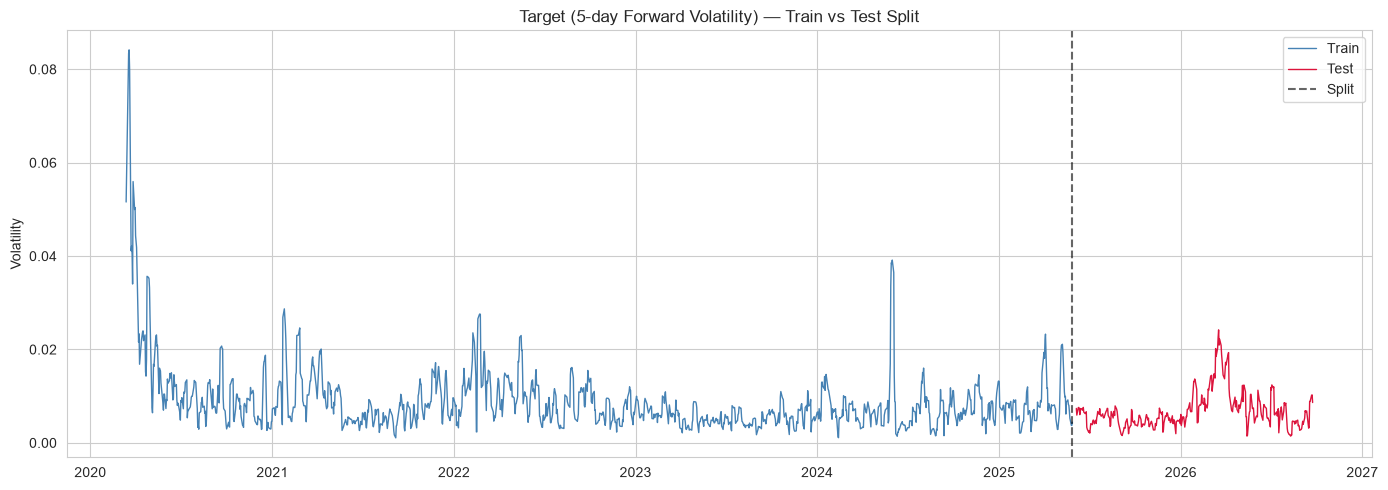

In [4]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(train_df.index, train_df[TARGET], label='Train', color='steelblue', linewidth=1)
ax.plot(test_df.index, test_df[TARGET], label='Test', color='crimson', linewidth=1)
ax.axvline(X_train.index.max(), color='black', linestyle='--', alpha=0.6, label='Split')
ax.set_title('Target (5-day Forward Volatility) — Train vs Test Split')
ax.set_ylabel('Volatility'); ax.legend()
plt.tight_layout()
plt.savefig('../reports/figures/09_train_test_split.png', dpi=120)
plt.show()

4.4 Feature Scale Comparison
Verify train and test distributions aren't wildly different (a common failure mode).

In [5]:
compare = pd.DataFrame({
    'train_mean': X_train.mean(),
    'test_mean':  X_test.mean(),
    'train_std':  X_train.std(),
    'test_std':   X_test.std(),
})
compare['mean_shift_%'] = ((compare['test_mean'] - compare['train_mean']) /
                           compare['train_mean'].replace(0, np.nan) * 100).round(1)
display(compare.round(4))

,train_mean,test_mean,train_std,test_std,mean_shift_%
Return,0.0007,-0.0002,0.0117,0.0077,-120.6
Return_lag1,0.0007,-0.0002,0.0120,0.0077,-123.5
Return_lag2,0.0007,-0.0002,0.0120,0.0077,-124.9
Return_lag3,0.0006,-0.0002,0.0120,0.0077,-128.8
Return_lag5,0.0006,-0.0002,0.0121,0.0077,-132.4
Return_lag10,0.0006,-0.0002,0.0121,0.0077,-126.3
AbsReturn_lag1,0.0077,0.0057,0.0091,0.0052,-26.1
AbsReturn_lag2,0.0077,0.0057,0.0091,0.0052,-25.9
AbsReturn_lag3,0.0078,0.0057,0.0092,0.0052,-26.2
AbsReturn_lag5,0.0078,0.0057,0.0092,0.0052,-26.3


4.5 Walk-Forward Validation (Set Up)
Instead of a single train/test split, walk-forward CV gives a more robust estimate of performance. We'll use TimeSeriesSplit from sklearn — expanding window with 5 folds.

In [14]:

import sys

print("Python executable:", sys.executable)
print("Python version:", sys.version)


Python executable: c:\Users\User\AppData\Local\Programs\Python\Python312\python.exe
Python version: 3.12.4 (tags/v3.12.4:8e8a4ba, Jun  6 2024, 19:30:16) [MSC v.1940 64 bit (AMD64)]


In [15]:

%pip show scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [16]:

%pip install scikit-learn==1.9.1

  Using cached scikit_learn-1.9.1-cp312-cp312-win_amd64.whl.metadata (9.3 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached scikit_learn-1.9.1-cp312-cp312-win_amd64.whl (8.3 MB)
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached threadpoolctl-3.7.0-py3-none-any.whl (26 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [17]:

import sklearn
from sklearn.model_selection import TimeSeriesSplit

print("scikit-learn version:", sklearn.__version__)
print("TimeSeriesSplit imported successfully!")

scikit-learn version: 1.9.1
TimeSeriesSplit imported successfully!


In [18]:
# Code - Walk-Forward Setup
from sklearn.model_selection import TimeSeriesSplit

N_SPLITS = 5
tscv = TimeSeriesSplit(n_splits=N_SPLITS, gap=FORWARD_WINDOW)

fold_info = []
for i, (tr_idx, va_idx) in enumerate(tscv.split(X_train)):
    fold_info.append({
        'fold': i + 1,
        'train_start': X_train.index[tr_idx[0]].date(),
        'train_end':   X_train.index[tr_idx[-1]].date(),
        'val_start':   X_train.index[va_idx[0]].date(),
        'val_end':     X_train.index[va_idx[-1]].date(),
        'n_train': len(tr_idx),
        'n_val':   len(va_idx),
    })

display(pd.DataFrame(fold_info))

,fold,train_start,train_end,val_start,val_end,n_train,n_val
0,1,2020-03-13,2021-01-13,2021-01-21,2021-12-03,209,214
1,2,2020-03-13,2021-11-26,2021-12-06,2022-10-13,423,214
2,3,2020-03-13,2022-10-06,2022-10-14,2023-08-24,637,214
3,4,2020-03-13,2023-08-17,2023-08-25,2024-07-15,851,214
4,5,2020-03-13,2024-07-08,2024-07-16,2025-05-28,1065,214


In [19]:
# Code - Save Split Indices
import os
os.makedirs('../data/processed/splits', exist_ok=True)

pd.Series(X_train.index).to_csv('../data/processed/splits/train_dates.csv', index=False, header=['Date'])
pd.Series(X_test.index).to_csv('../data/processed/splits/test_dates.csv', index=False, header=['Date'])

print("Saved train/test date indices.")
print(f"X_train: {X_train.shape}, X_test: {X_test.shape}")
print(f"y_train: {y_train.shape}, y_test: {y_test.shape}")

Saved train/test date indices.
X_train: (1284, 20), X_test: (323, 20)
y_train: (1284,), y_test: (323,)



Phase 5: Model Training & Comparison
Train 5 models on the same train/test split:

1. Persistence baseline (target = current trailing vol)

2. Linear Regression

3. XGBoost (base paper model)

4. LightGBM (extension)

5. CatBoost (extension)

All tree models get Optuna hyperparameter tuning using walk-forward CV.

In [6]:
import os, sys, warnings
warnings.filterwarnings('ignore')
sys.path.append('..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import optuna

from sklearn.linear_model import LinearRegression
from src.evaluation import evaluate_regression, directional_accuracy, regime_wise_metrics
from src.models import (build_xgboost, build_lightgbm, build_catboost,
                        xgb_objective, lgbm_objective, catboost_objective)

optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (14, 5)

# Reload from Phase 4
df = pd.read_csv('../data/processed/nsei_features.csv', parse_dates=['Date'], index_col='Date')
FORWARD_WINDOW = 5
TARGET = 'Target_Volatility'
EXCLUDE = [TARGET, 'Regime', 'Open', 'High', 'Low', 'Close', 'Volume',
           'High_Low_Range', 'Volume_Change',
           'MA_5', 'MA_20', 'MA_50', 'Volume_MA_5', 'Volume_MA_20',
           'MACD', 'MACD_signal']
FEATURES = [c for c in df.columns if c not in EXCLUDE]

train_end = int(len(df) * 0.80)
train_df = df.iloc[:train_end - FORWARD_WINDOW].copy()
test_df  = df.iloc[train_end:].copy()

X_train, y_train = train_df[FEATURES], train_df[TARGET]
X_test,  y_test  = test_df[FEATURES],  test_df[TARGET]

# Reference for directional accuracy: current trailing vol at time t
reference_test = test_df['Vol_rolling_5']

print(f"Train: {X_train.shape}  Test: {X_test.shape}")
print(f"Features used: {len(FEATURES)}")

Train: (1284, 20)  Test: (323, 20)
Features used: 20


In [5]:
import sys
!{sys.executable} -m pip install xgboost lightgbm catboost optuna

  Using cached xgboost-3.4.1-py3-none-win_amd64.whl.metadata (2.0 kB)
  Using cached lightgbm-4.7.0-py3-none-win_amd64.whl.metadata (18 kB)
  Using cached catboost-1.2.10-cp312-cp312-win_amd64.whl.metadata (1.5 kB)
  Using cached graphviz-0.21-py3-none-any.whl.metadata (12 kB)
  Using cached plotly-7.1.0-py3-none-any.whl.metadata (8.8 kB)
Using cached xgboost-3.4.1-py3-none-win_amd64.whl (48.9 MB)
Using cached lightgbm-4.7.0-py3-none-win_amd64.whl (1.4 MB)
Using cached catboost-1.2.10-cp312-cp312-win_amd64.whl (100.2 MB)
Using cached graphviz-0.21-py3-none-any.whl (47 kB)
Using cached plotly-7.1.0-py3-none-any.whl (9.7 MB)



[notice] A new release of pip is available: 24.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


5.1a Baseline — Persistence
The simplest possible forecast: "tomorrow's volatility = today's volatility". For our 5-day forward target, the persistence prediction is simply the current Vol_rolling_5.

In [7]:
y_pred_persistence = test_df['Vol_rolling_5'].values

results = {}
results['Persistence'] = {
    'y_pred':  y_pred_persistence,
    'metrics': evaluate_regression(y_test, y_pred_persistence),
    'dir_acc': directional_accuracy(y_test, y_pred_persistence, reference_test),
}
print("Persistence baseline:")
print(results['Persistence']['metrics'])
print(f"Directional accuracy: {results['Persistence']['dir_acc']:.3f}")

Persistence baseline:
{'MAE': 0.0025918063779519626, 'RMSE': 0.003537320040425416, 'R2': 0.19398158802118426}
Directional accuracy: 0.000


5.1b Baseline — Linear Regression
Fit a linear regression on all features. Since some features are highly collinear (e.g., multiple rolling vol features), we expect mediocre performance — the base paper also finds linear models struggle with nonlinear volatility.

In [8]:
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

results['LinearRegression'] = {
    'y_pred':  y_pred_lr,
    'metrics': evaluate_regression(y_test, y_pred_lr),
    'dir_acc': directional_accuracy(y_test, y_pred_lr, reference_test),
}
print("Linear Regression:")
print(results['LinearRegression']['metrics'])
print(f"Directional accuracy: {results['LinearRegression']['dir_acc']:.3f}")

Linear Regression:
{'MAE': 0.002326347289653141, 'RMSE': 0.0030584094348796347, 'R2': 0.397457752598498}
Directional accuracy: 0.653


5.4 Tune XGBoost with Optuna
30 trials, 5-fold walk-forward CV, minimizing RMSE. gap=5 prevents the forward-looking target from leaking across folds.

⏱️ This may take ~3–5 minutes.

In [9]:
# XGBoost tuning

study_xgb = optuna.create_study(direction='minimize')
study_xgb.optimize(
    lambda t: xgb_objective(t, X_train, y_train, gap=FORWARD_WINDOW),
    n_trials=30, show_progress_bar=True,
)
print(f"Best XGBoost CV RMSE: {study_xgb.best_value:.6f}")
print("Best params:", study_xgb.best_params)

Best trial: 23. Best value: 0.00523238: 100%|██████████| 30/30 [06:38<00:00, 13.27s/it]

Best XGBoost CV RMSE: 0.005232
Best params: {'n_estimators': 447, 'max_depth': 5, 'learning_rate': 0.006390617510100914, 'subsample': 0.8806949151491632, 'colsample_bytree': 0.8816549821234886, 'reg_alpha': 0.03253478090826487, 'reg_lambda': 0.3216740535021607, 'min_child_weight': 10}


In [10]:
# XGBoost final fit & eval

xgb_model = build_xgboost(study_xgb.best_params)
xgb_model.fit(X_train, y_train)
y_pred_xgb = xgb_model.predict(X_test)

results['XGBoost'] = {
    'y_pred':  y_pred_xgb,
    'metrics': evaluate_regression(y_test, y_pred_xgb),
    'dir_acc': directional_accuracy(y_test, y_pred_xgb, reference_test),
    'model':   xgb_model,
    'params':  study_xgb.best_params,
}
print("XGBoost test performance:")
print(results['XGBoost']['metrics'])
print(f"Directional accuracy: {results['XGBoost']['dir_acc']:.3f}")

XGBoost test performance:
{'MAE': 0.0023577595919671746, 'RMSE': 0.002992980841121883, 'R2': 0.4229623811407027}
Directional accuracy: 0.647


5.3a Tune LightGBM
⏱️ ~3–5 minutes.

In [11]:
# LightGBM tuning

study_lgbm = optuna.create_study(direction='minimize')
study_lgbm.optimize(
    lambda t: lgbm_objective(t, X_train, y_train, gap=FORWARD_WINDOW),
    n_trials=30, show_progress_bar=True,
)
print(f"Best LightGBM CV RMSE: {study_lgbm.best_value:.6f}")
print("Best params:", study_lgbm.best_params)

Best trial: 12. Best value: 0.00523038: 100%|██████████| 30/30 [00:50<00:00,  1.70s/it]

Best LightGBM CV RMSE: 0.005230
Best params: {'n_estimators': 210, 'num_leaves': 20, 'max_depth': 4, 'learning_rate': 0.008135500288043723, 'subsample': 0.9514437590531288, 'colsample_bytree': 0.8304196222392358, 'reg_alpha': 0.050257886035607574, 'reg_lambda': 4.852366863440559e-07, 'min_child_samples': 36}


In [12]:
# LightGBM final fit & eval

lgbm_model = build_lightgbm(study_lgbm.best_params)
lgbm_model.fit(X_train, y_train)
y_pred_lgbm = lgbm_model.predict(X_test)

results['LightGBM'] = {
    'y_pred':  y_pred_lgbm,
    'metrics': evaluate_regression(y_test, y_pred_lgbm),
    'dir_acc': directional_accuracy(y_test, y_pred_lgbm, reference_test),
    'model':   lgbm_model,
    'params':  study_lgbm.best_params,
}
print("LightGBM test performance:")
print(results['LightGBM']['metrics'])
print(f"Directional accuracy: {results['LightGBM']['dir_acc']:.3f}")

LightGBM test performance:
{'MAE': 0.00244342203001326, 'RMSE': 0.003042225778381374, 'R2': 0.40381761855707066}
Directional accuracy: 0.647


5.3b Tune CatBoost
⏱️ ~4–6 minutes (CatBoost is slower than LGBM/XGB).

In [13]:
# CatBoost tuning

study_cat = optuna.create_study(direction='minimize')
study_cat.optimize(
    lambda t: catboost_objective(t, X_train, y_train, gap=FORWARD_WINDOW),
    n_trials=25, show_progress_bar=True,
)
print(f"Best CatBoost CV RMSE: {study_cat.best_value:.6f}")
print("Best params:", study_cat.best_params)

Best trial: 24. Best value: 0.00478938: 100%|██████████| 25/25 [1:53:50<00:00, 273.21s/it]  

Best CatBoost CV RMSE: 0.004789
Best params: {'iterations': 603, 'depth': 9, 'learning_rate': 0.010723356759861954, 'l2_leaf_reg': 9.876451998333593, 'bagging_temperature': 0.42564918172569666, 'random_strength': 3.61287239680642}


In [14]:
# CatBoost final fit & eval

cat_model = build_catboost(study_cat.best_params)
cat_model.fit(X_train, y_train)
y_pred_cat = cat_model.predict(X_test)

results['CatBoost'] = {
    'y_pred':  y_pred_cat,
    'metrics': evaluate_regression(y_test, y_pred_cat),
    'dir_acc': directional_accuracy(y_test, y_pred_cat, reference_test),
    'model':   cat_model,
    'params':  study_cat.best_params,
}
print("CatBoost test performance:")
print(results['CatBoost']['metrics'])
print(f"Directional accuracy: {results['CatBoost']['dir_acc']:.3f}")

CatBoost test performance:
{'MAE': 0.002334180672135807, 'RMSE': 0.002992149527515019, 'R2': 0.42328288610241493}
Directional accuracy: 0.656


5.5 Model Comparison

In [16]:
# comparison table

import os
os.makedirs('../reports/tables', exist_ok=True)
rows = []
for name, r in results.items():
    rows.append({
        'Model': name,
        'MAE':  round(r['metrics']['MAE'],  6),
        'RMSE': round(r['metrics']['RMSE'], 6),
        'R²':   round(r['metrics']['R2'],   4),
        'Dir. Acc.': round(r['dir_acc'],    3),
    })

comparison = pd.DataFrame(rows).sort_values('RMSE').reset_index(drop=True)
display(comparison)
comparison.to_csv('../reports/tables/model_comparison.csv', index=False)

,Model,MAE,RMSE,R²,Dir. Acc.
0,CatBoost,0.002334,0.002992,0.4233,0.656
1,XGBoost,0.002358,0.002993,0.4230,0.647
2,LightGBM,0.002443,0.003042,0.4038,0.647
3,LinearRegression,0.002326,0.003058,0.3975,0.653
4,Persistence,0.002592,0.003537,0.1940,0.000


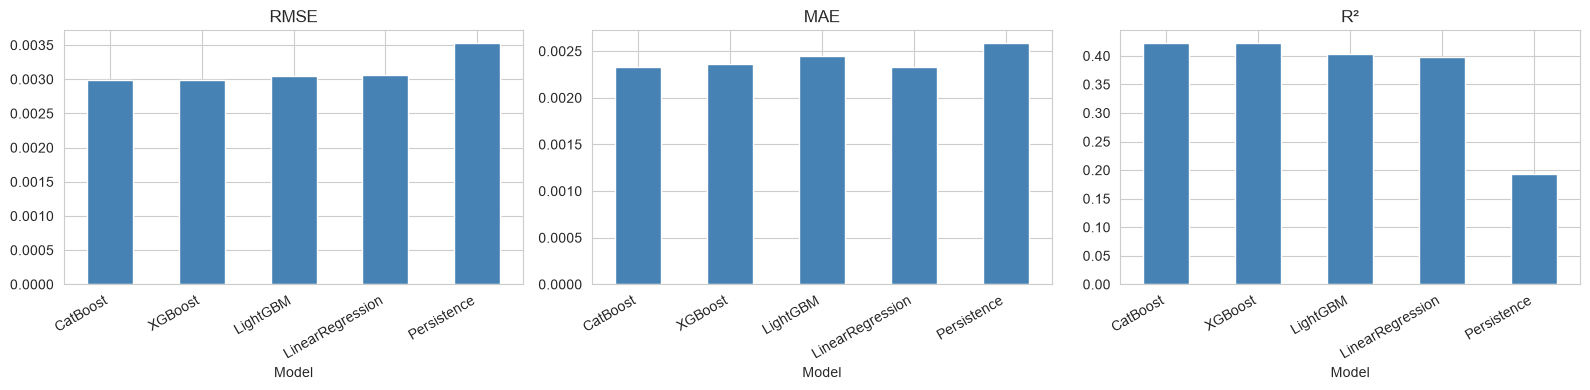

In [18]:
# barchart comparison

# fig, axes = plt.subplots(1, 3, figsize=(16, 4))
# for ax, metric in zip(axes, ['RMSE', 'MAE', 'R2']):
#     comparison.plot.bar(x='Model', y=metric, ax=ax, legend=False, color='steelblue')
#     ax.set_title(metric); ax.set_xticklabels(comparison['Model'], rotation=30, ha='right')
# plt.tight_layout()
# os.makedirs('../reports/figures', exist_ok=True)
# plt.savefig('../reports/figures/10_model_comparison.png', dpi=120)
# plt.show()

import os
os.makedirs('../reports/figures', exist_ok=True)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, metric in zip(axes, ['RMSE', 'MAE', 'R²']):
    comparison.plot.bar(x='Model', y=metric, ax=ax, legend=False, color='steelblue')
    ax.set_title(metric)
    ax.set_xticklabels(comparison['Model'], rotation=30, ha='right')

plt.tight_layout()
plt.savefig('../reports/figures/10_model_comparison.png', dpi=120)
plt.show()

Regime-Wise Performance
Split test-set errors by volatility regime (Low/Medium/High) using the Regime column from Phase 3.

In [19]:
# regime wise metrics

best_model_name = comparison.iloc[0]['Model']
best_pred = results[best_model_name]['y_pred']

regime_table = regime_wise_metrics(y_test, best_pred, test_df['Regime'])
print(f"Regime-wise metrics for best model: {best_model_name}")
display(regime_table.round(6))

Regime-wise metrics for best model: CatBoost


,MAE,RMSE,R2
High,0.003446,0.004398,0.348712
Medium,0.002594,0.003274,-0.225771
Low,0.001943,0.002373,-0.307819


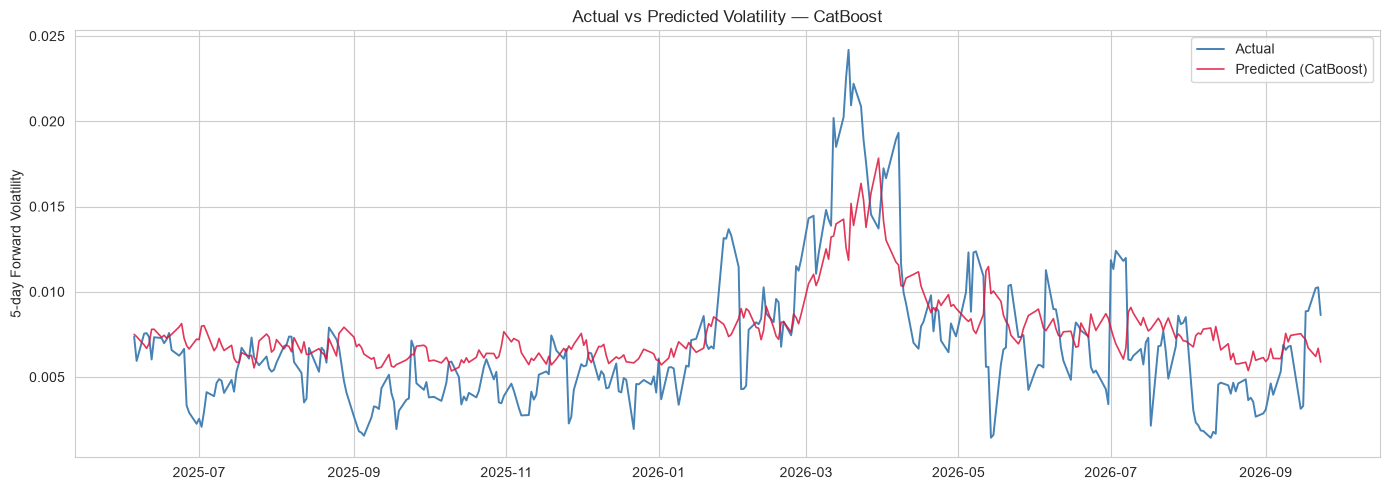

In [20]:
# actual output vs prediction plot

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(y_test.index, y_test.values, label='Actual', color='steelblue', linewidth=1.4)
ax.plot(y_test.index, best_pred, label=f'Predicted ({best_model_name})',
        color='crimson', linewidth=1.2, alpha=0.85)
ax.set_title(f'Actual vs Predicted Volatility — {best_model_name}')
ax.set_ylabel('5-day Forward Volatility'); ax.legend()
plt.tight_layout()
plt.savefig('../reports/figures/11_actual_vs_predicted.png', dpi=120)
plt.show()

Save Artifacts
Save all trained models and the comparison table for Phase 6 (SHAP) and Phase 7 (dashboard).

In [21]:
import joblib
os.makedirs('../models', exist_ok=True)

for name, r in results.items():
    if 'model' in r:
        joblib.dump(r['model'], f'../models/{name.lower()}_model.pkl')

# Save metadata
meta = {
    'features': FEATURES,
    'target': TARGET,
    'forward_window': FORWARD_WINDOW,
    'best_model': best_model_name,
    'test_dates': [str(d.date()) for d in y_test.index],
}
joblib.dump(meta, '../models/metadata.pkl')

print(f"Saved {sum('model' in r for r in results.values())} models to ../models/")
print(f"Best model: {best_model_name}")

Saved 3 models to ../models/
Best model: CatBoost
